In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

**Veri Setinin Tanımı**

Bu çalışmada kullanılan veri seti, kredi kartı müşterilerinin finansal davranışlarını içeren ve kümeleme analizi için sıklıkla kullanılan **Credit Card Dataset** veri setidir. Veri seti, müşterilerin harcama alışkanlıklarını ve kredi kullanım davranışlarını analiz etmeye olanak sağlamaktadır.

**Veri Setinin Boyutu ve Yapısı**

-*Toplam gözlem sayısı*: 8950 müşteri

-*Toplam değişken sayısı*: 18 özellik (feature)

-*Veri tipi*: Tamamen sayısal verilerden oluşmaktadır.

-*Her satır*: Bir müşteriyi temsil etmektedir.


*Veri setinde yer alan bazı temel değişkenler şunlardır:*

-**BALANCE**: Müşterinin mevcut hesap bakiyesi

-**PURCHASES:** Toplam alışveriş tutarı

-**CREDIT_LIMIT**: Kredi kartı limiti

-**PAYMENTS**: Yapılan toplam ödeme miktarı

-**TENURE:** Müşterinin sistemde bulunduğu süre


In [2]:
# Kredi kartı müşteri verisi DataFrame olarak yüklendi ve ilk 5 gözlem incelendi.
df = pd.read_csv("CC GENERAL.csv")
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [3]:
# Değişkenlerin veri tipleri (Dtype) ve satır-sütun sayıları kontrol ediliyor.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [4]:
# Sayısal değişkenlerin betimsel istatistikleri (ortalama, std, min, max, çeyreklikler) hesaplanıyor.
df.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


In [5]:
# Eksik veri kontrolü
df.isnull().sum().sort_values(ascending=False)

MINIMUM_PAYMENTS                    313
CREDIT_LIMIT                          1
CUST_ID                               0
BALANCE                               0
PRC_FULL_PAYMENT                      0
PAYMENTS                              0
PURCHASES_TRX                         0
CASH_ADVANCE_TRX                      0
CASH_ADVANCE_FREQUENCY                0
PURCHASES_INSTALLMENTS_FREQUENCY      0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_FREQUENCY                   0
CASH_ADVANCE                          0
INSTALLMENTS_PURCHASES                0
ONEOFF_PURCHASES                      0
PURCHASES                             0
BALANCE_FREQUENCY                     0
TENURE                                0
dtype: int64

In [6]:
# CUST_ID analitik veya istatistiksel bir değer taşımadığı için eğitim verisinden (X) çıkarılıyor.
df = df.drop(columns=["CUST_ID"])
X = df.copy()

In [7]:
#Model Kurulumu
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2)),  # görselleştirme için
    ("kmeans", KMeans(random_state=42))
])

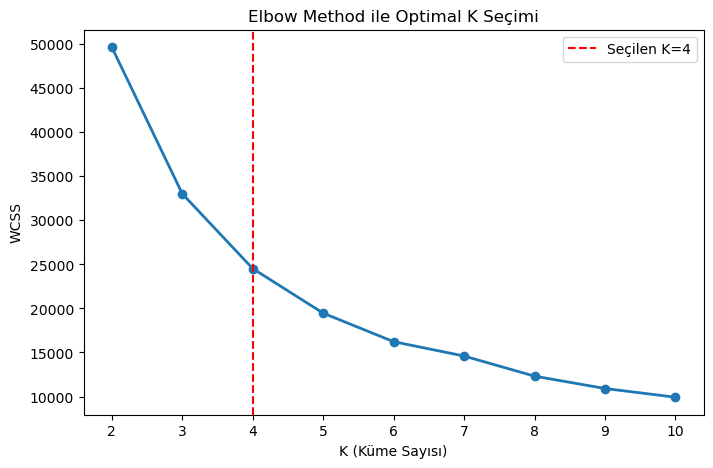

In [8]:
# Optimal K (Küme) sayısını belirlemek için Elbow (Dirsek) Metodu uygulanıyor.
# wcss: Within-Cluster Sum of Square (Küme İçi Hata Kareler Toplamı)
wcss = []

for k in range(2, 11):
    pipeline.set_params(kmeans__n_clusters=k)
    pipeline.fit(X)
    wcss.append(pipeline.named_steps["kmeans"].inertia_)

plt.figure(figsize=(8,5))

k_values = range(2, 11)
plt.plot(k_values, wcss, marker='o', linewidth=2)

plt.title("Elbow Method ile Optimal K Seçimi")
plt.xlabel("K (Küme Sayısı)")
plt.ylabel("WCSS")

plt.axvline(x=4, color='red', linestyle='--', label='Seçilen K=4')
plt.legend()

plt.show()

In [9]:
# Elbow grafiğine göre K=4 seçilerek Pipeline eğitiliyor ve müşteriler kümeleniyor.
optimal_k = 4

pipeline.set_params(kmeans__n_clusters=optimal_k)
pipeline.fit(X)

labels = pipeline.predict(X)
X_transformed = pipeline[:-1].transform(X)

In [13]:
# Performans Analizi: Silhouette Skoru (Kümelerin birbirinden ne kadar iyi ayrıştığını ölçer)
score = silhouette_score(X_transformed, labels)
print(f"Modelin Silhouette Skoru: {score:.4f}")

Modelin Silhouette Skoru: 0.4077


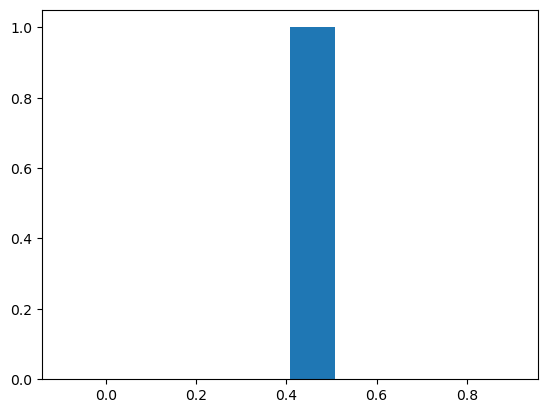

In [14]:
plt.hist(score)
plt.show()

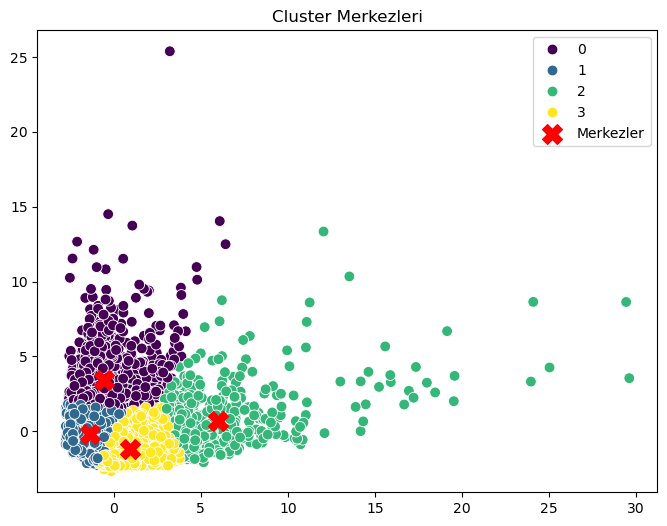

In [11]:
# PCA ile 2 boyuta indirgenen verideki kümelerin dağılımı görselleştiriliyor.centers = pipeline.named_steps["kmeans"].cluster_centers_
centers = pipeline.named_steps["kmeans"].cluster_centers_
plt.figure(figsize=(8,6))

sns.scatterplot(
    x=X_transformed[:,0],
    y=X_transformed[:,1],
    hue=labels,
    palette="viridis",
    s=60
)

plt.scatter(
    centers[:,0], centers[:,1],
    c='red', s=200, marker='X', label='Merkezler'
)

plt.legend()
plt.title("Cluster Merkezleri")
plt.show()

In [12]:
# Her bir kümenin karakteristik özelliklerini anlamak için değişkenlerin küme bazlı ortalamaları hesaplanıyor.
df["Cluster"] = labels

cluster_summary = df.groupby("Cluster").mean()
print(cluster_summary)

             BALANCE  BALANCE_FREQUENCY    PURCHASES  ONEOFF_PURCHASES  \
Cluster                                                                  
0        4508.592174           0.963457   462.914437        300.368650   
1        1014.708276           0.800024   222.981330        157.502591   
2        3401.840056           0.988427  6894.613917       4511.889901   
3         823.929519           0.919745  1236.281903        621.637778   

         INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
Cluster                                                              
0                    162.645201   4403.476123             0.266204   
1                     65.807853    615.077919             0.190014   
2                   2383.916859    773.154467             0.954443   
3                    614.849145    147.397313             0.862380   

         ONEOFF_PURCHASES_FREQUENCY  PURCHASES_INSTALLMENTS_FREQUENCY  \
Cluster                                                      

### K-Means Kümeleme Sonuçlarının Yorumlanması
Yukarıdaki grafik ve ortalama tablosu incelendiğinde müşteriler 4 ana segmente ayrılmıştır:

* **Cluster 0 (Pasif Müşteri):** Düşük harcama ve düşük kredi kullanımına sahip standart kitle.
* **Cluster 1 (Değerli Müşteri):** Harcama frekansı ve miktarı yüksek, banka için karlılığı en yüksek segment.
* **Cluster 2 (Riskli Müşteri):** Kredi limitini yüksek oranda nakit avans için kullanan ve borçlanma eğilimi yüksek olan kitle.
* **Cluster 3 (Orta Segment):** Ortalama harcama ve ödeme dengesine sahip, potansiyel vadeden müşteri grubu.